In [69]:
import gym
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
from collections import deque
import random
import matplotlib.pyplot as plt
import torch.nn.functional as F
from torch.distributions import Categorical


In [98]:
def set_seed(seed):
    torch.manual_seed(seed)
    np.random.seed(seed)
    random.seed(seed)


In [104]:
class ActorCritic(nn.Module):
    def __init__(self, state_dim, action_dim, hidden_dim=128):
        super().__init__()
        self.fc1 = nn.Linear(state_dim, hidden_dim)
        self.fc2 = nn.Linear(hidden_dim, hidden_dim)
        self.policy_head = nn.Linear(hidden_dim, action_dim)  # Actor
        self.value_head = nn.Linear(hidden_dim, 1)             # Critic

    def forward(self, state):
        x = F.relu(self.fc1(state))
        x = F.relu(self.fc2(x))
        policy = F.softmax(self.policy_head(x), dim=-1)
        value = self.value_head(x)
        return policy, value


In [105]:
def train_actor_critic(config, seed=0):
    set_seed(seed)
    env = gym.make("CartPole-v1")
    state_dim = env.observation_space.shape[0]
    action_dim = env.action_space.n

    model = ActorCritic(state_dim, action_dim, hidden_dim=config["hidden_dim"])
    optimizer = optim.Adam(model.parameters(), lr=config["lr"])
    
    episode_rewards, env_steps = [], []
    total_steps = 0

    while total_steps < config["max_env_steps"]:
        state, _ = env.reset()
        done = False
        total_reward = 0

        while not done:
            state_tensor = torch.tensor(state, dtype=torch.float32)
            action_probs, state_value = model(state_tensor)
            dist = torch.distributions.Categorical(action_probs)
            action = dist.sample()

            next_state, reward, terminated, truncated, _ = env.step(action.item())
            done = terminated or truncated

            next_state_tensor = torch.tensor(next_state, dtype=torch.float32)
            _, next_state_value = model(next_state_tensor)

            target_value = reward + (0 if done else config["gamma"] * next_state_value.item())
            advantage = target_value - state_value.item()

            actor_loss = -dist.log_prob(action) * advantage
            critic_loss = F.mse_loss(state_value.squeeze(), torch.tensor(target_value))
            loss = actor_loss + critic_loss

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            state = next_state
            total_reward += reward
            total_steps +=1

        episode_rewards.append(total_reward)
        env_steps.append(total_steps)
        print(f"[AC] Step {total_steps}/{config['max_env_steps']} | Reward: {total_reward:.2f}")

    env.close()
    return episode_rewards, env_steps


In [106]:
def train_A2C(config, seed=0):
    set_seed(seed)
    env = gym.make("CartPole-v1")
    state_dim = env.observation_space.shape[0]
    action_dim = env.action_space.n
    model = ActorCritic(state_dim, action_dim, hidden_dim=config["hidden_dim"])
    optimizer = optim.Adam(model.parameters(), lr=config["lr"])

    episode_rewards, env_steps = [], []
    total_steps = 0

    while total_steps < config["max_env_steps"]:
        state, _ = env.reset()
        done=False
        total_reward = 0
        log_probs, values, rewards,entropies = [], [], [], []

        while not done:
            state_tensor = torch.tensor(state, dtype=torch.float32).unsqueeze(0)
            action_probs, state_value = model(state_tensor)
            dist = Categorical(action_probs)
            action = dist.sample()

            log_prob = dist.log_prob(action)
            entropy = dist.entropy()

            next_state, reward, terminated, truncated, _ = env.step(action.item())
            done = terminated or truncated

            log_probs.append(log_prob)
            values.append(state_value)
            rewards.append(reward)
            entropies.append(entropy)

            state = next_state
            total_reward += reward
            total_steps += 1

        returns = []
        G = 0
        for r in reversed(rewards):
            G = r + config["gamma"] * G
            returns.insert(0, G)
        returns = torch.tensor(returns, dtype=torch.float32)
        values = torch.cat(values).squeeze()
        advantages = returns - values.detach()

        log_probs = torch.stack(log_probs)
        entropies = torch.stack(entropies)

        actor_loss = - (log_probs * advantages).sum()
        critic_loss = F.mse_loss(values, returns)
        entropy_bonus = entropies.sum()

        loss = actor_loss + critic_loss - 0.01*entropy_bonus

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        episode_rewards.append(total_reward)
        env_steps.append(total_steps)
        print(f"[A2C] Step {total_steps}/{config['max_env_steps']} | Reward: {total_reward:.2f}")

    env.close()
    return episode_rewards, env_steps

In [107]:
def moving_average(data, window_size=50):
    return np.convolve(data, np.ones(window_size) / window_size, mode="valid")

def plot_results(results, title, label_prefix):
    plt.figure(figsize=(12, 6))
    for i, (rewards, steps) in enumerate(results):
        smoothed = moving_average(rewards)
        aligned_steps = steps[len(steps) - len(smoothed):]
        plt.plot(aligned_steps, smoothed, label=f"{label_prefix} Run {i+1}", linewidth=1)
    plt.xlabel("Environment Steps")
    plt.ylabel("Smoothed Episode Reward (50)")
    plt.title(title)
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()


In [ ]:
config = {
    "lr": 5e-4,
    "gamma": 0.99,
    "hidden_dim": 128,
    "max_env_steps": 100000
}

ac_results = []

for i in range(5):
    print(f"\n=== AC Run {i+1} ===")
    ac_rewards, ac_steps = train_actor_critic(config, seed=42 + i)
    ac_results.append((ac_rewards, ac_steps))


    # print(f"\n=== A2C Run {i+1} ===")
    # a2c_rewards, a2c_steps = train_A2C(config, seed=42 + i)
    # a2c_results.append((a2c_rewards, a2c_steps))




=== AC Run 1 ===
[AC] Step 17/100000 | Reward: 17.00
[AC] Step 28/100000 | Reward: 11.00
[AC] Step 50/100000 | Reward: 22.00
[AC] Step 73/100000 | Reward: 23.00
[AC] Step 90/100000 | Reward: 17.00
[AC] Step 113/100000 | Reward: 23.00
[AC] Step 127/100000 | Reward: 14.00
[AC] Step 137/100000 | Reward: 10.00
[AC] Step 148/100000 | Reward: 11.00
[AC] Step 157/100000 | Reward: 9.00
[AC] Step 170/100000 | Reward: 13.00
[AC] Step 179/100000 | Reward: 9.00
[AC] Step 189/100000 | Reward: 10.00
[AC] Step 198/100000 | Reward: 9.00
[AC] Step 207/100000 | Reward: 9.00
[AC] Step 217/100000 | Reward: 10.00
[AC] Step 227/100000 | Reward: 10.00
[AC] Step 236/100000 | Reward: 9.00
[AC] Step 245/100000 | Reward: 9.00
[AC] Step 254/100000 | Reward: 9.00
[AC] Step 265/100000 | Reward: 11.00
[AC] Step 273/100000 | Reward: 8.00
[AC] Step 282/100000 | Reward: 9.00
[AC] Step 291/100000 | Reward: 9.00
[AC] Step 301/100000 | Reward: 10.00
[AC] Step 310/100000 | Reward: 9.00
[AC] Step 318/100000 | Reward: 8.00


In [115]:
a2c_results = []


In [118]:
a2c_results = []
for i in range(5):

    print(f"\n=== A2C Run {i+1} ===")
    a2c_rewards, a2c_steps = train_A2C(config, seed=42 + i)
    a2c_results.append((a2c_rewards, a2c_steps))


=== A2C Run 1 ===
[A2C] Step 27/100000 | Reward: 27.00
[A2C] Step 54/100000 | Reward: 27.00
[A2C] Step 68/100000 | Reward: 14.00
[A2C] Step 91/100000 | Reward: 23.00
[A2C] Step 117/100000 | Reward: 26.00
[A2C] Step 133/100000 | Reward: 16.00
[A2C] Step 152/100000 | Reward: 19.00
[A2C] Step 175/100000 | Reward: 23.00
[A2C] Step 188/100000 | Reward: 13.00
[A2C] Step 210/100000 | Reward: 22.00
[A2C] Step 227/100000 | Reward: 17.00
[A2C] Step 259/100000 | Reward: 32.00
[A2C] Step 288/100000 | Reward: 29.00
[A2C] Step 319/100000 | Reward: 31.00
[A2C] Step 343/100000 | Reward: 24.00
[A2C] Step 360/100000 | Reward: 17.00
[A2C] Step 376/100000 | Reward: 16.00
[A2C] Step 387/100000 | Reward: 11.00
[A2C] Step 433/100000 | Reward: 46.00
[A2C] Step 506/100000 | Reward: 73.00
[A2C] Step 518/100000 | Reward: 12.00
[A2C] Step 562/100000 | Reward: 44.00
[A2C] Step 579/100000 | Reward: 17.00
[A2C] Step 601/100000 | Reward: 22.00
[A2C] Step 628/100000 | Reward: 27.00
[A2C] Step 644/100000 | Reward: 16.

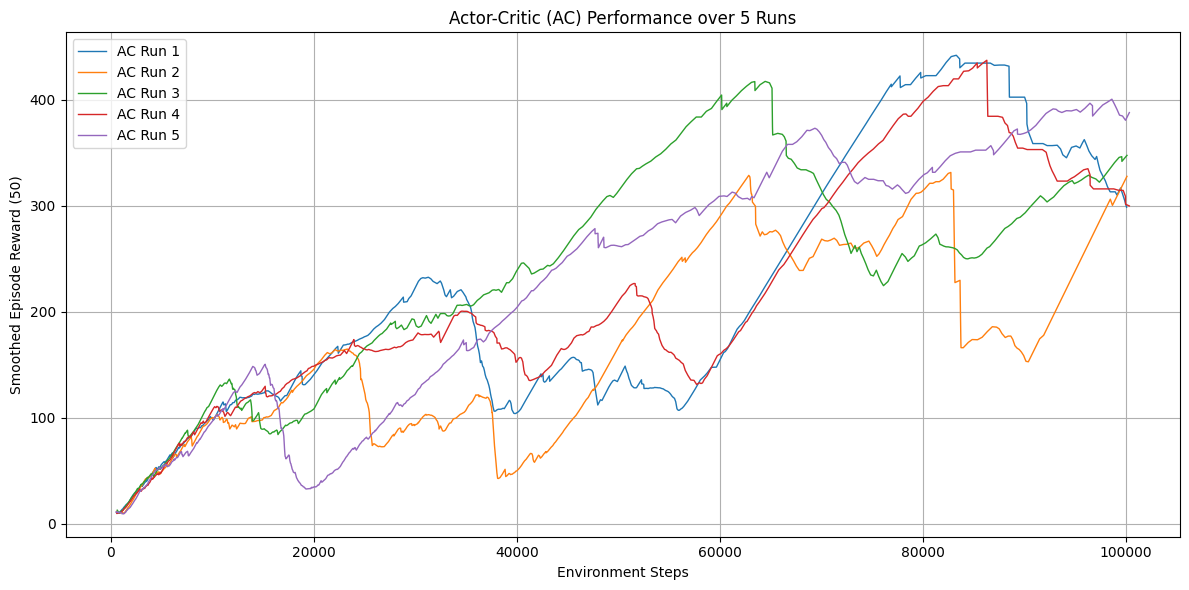

In [116]:
plot_results(ac_results, "Actor-Critic (AC) Performance over 5 Runs", "AC")


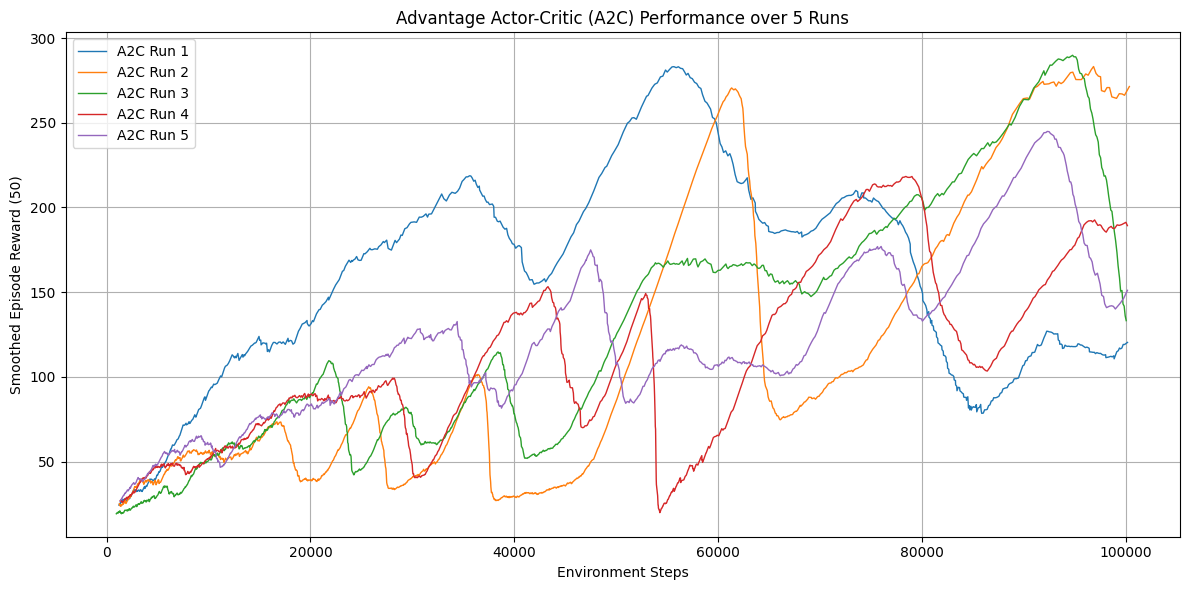

In [119]:
plot_results(a2c_results, "Advantage Actor-Critic (A2C) Performance over 5 Runs", "A2C")

In [113]:
print(a2c_results)

[]
